In [1]:
from typing import Optional

from datetime import datetime

from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, clone
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, ElasticNet
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

import matplotlib.pyplot as plt


In [2]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

In [3]:
data_dir = Path.cwd().parent / 'data'

In [4]:
dirs = ['data_Q1_2025', 'data_Q1_2026']

In [5]:
%%time
sample = pd.read_csv(next((data_dir / dirs[0]).glob('*.csv')))

CPU times: user 1.37 s, sys: 91.2 ms, total: 1.46 s
Wall time: 1.47 s


In [6]:
chosen_columns = list(sample.columns.tolist()[:10]) + list(sample.columns.tolist()[12::2])
print(chosen_columns)

['date', 'serial_number', 'model', 'capacity_bytes', 'failure', 'datacenter', 'cluster_id', 'vault_id', 'pod_id', 'pod_slot_num', 'smart_1_raw', 'smart_2_raw', 'smart_3_raw', 'smart_4_raw', 'smart_5_raw', 'smart_7_raw', 'smart_8_raw', 'smart_9_raw', 'smart_10_raw', 'smart_11_raw', 'smart_12_raw', 'smart_13_raw', 'smart_15_raw', 'smart_16_raw', 'smart_17_raw', 'smart_18_raw', 'smart_22_raw', 'smart_23_raw', 'smart_24_raw', 'smart_27_raw', 'smart_71_raw', 'smart_82_raw', 'smart_90_raw', 'smart_160_raw', 'smart_161_raw', 'smart_163_raw', 'smart_164_raw', 'smart_165_raw', 'smart_166_raw', 'smart_167_raw', 'smart_168_raw', 'smart_169_raw', 'smart_170_raw', 'smart_171_raw', 'smart_172_raw', 'smart_173_raw', 'smart_174_raw', 'smart_175_raw', 'smart_176_raw', 'smart_177_raw', 'smart_178_raw', 'smart_179_raw', 'smart_180_raw', 'smart_181_raw', 'smart_182_raw', 'smart_183_raw', 'smart_184_raw', 'smart_187_raw', 'smart_188_raw', 'smart_189_raw', 'smart_190_raw', 'smart_191_raw', 'smart_192_raw', 

In [7]:
sample[chosen_columns].describe()

,capacity_bytes,failure,cluster_id,vault_id,pod_id,pod_slot_num,smart_1_raw,smart_2_raw,smart_3_raw,smart_4_raw,smart_5_raw,smart_7_raw,smart_8_raw,smart_9_raw,smart_10_raw,smart_11_raw,smart_12_raw,smart_13_raw,smart_15_raw,smart_16_raw,smart_17_raw,smart_18_raw,smart_22_raw,smart_23_raw,smart_24_raw,smart_27_raw,smart_71_raw,smart_82_raw,smart_90_raw,smart_160_raw,smart_161_raw,smart_163_raw,smart_164_raw,smart_165_raw,smart_166_raw,smart_167_raw,smart_168_raw,smart_169_raw,smart_170_raw,smart_171_raw,smart_172_raw,smart_173_raw,smart_174_raw,smart_175_raw,smart_176_raw,smart_177_raw,smart_178_raw,smart_179_raw,smart_180_raw,smart_181_raw,smart_182_raw,smart_183_raw,smart_184_raw,smart_187_raw,smart_188_raw,smart_189_raw,smart_190_raw,smart_191_raw,smart_192_raw,smart_193_raw,smart_194_raw,smart_195_raw,smart_196_raw,smart_197_raw,smart_198_raw,smart_199_raw,smart_200_raw,smart_201_raw,smart_202_raw,smart_206_raw,smart_210_raw,smart_211_raw,smart_212_raw,smart_218_raw,smart_220_raw,smart_222_raw,smart_223_raw,smart_224_raw,smart_225_raw,smart_226_raw,smart_230_raw,smart_231_raw,smart_232_raw,smart_233_raw,smart_234_raw,smart_235_raw,smart_240_raw,smart_241_raw,smart_242_raw,smart_244_raw,smart_245_raw,smart_246_raw,smart_247_raw,smart_248_raw,smart_250_raw,smart_251_raw,smart_252_raw,smart_254_raw,smart_255_raw
count,3.091840e+05,309184.000000,309184.000000,309184.000000,309184.000000,304922.000000,3.084410e+05,198163.000000,305813.000000,305813.000000,306917.000000,3.058130e+05,198163.000000,308751.000000,3.058130e+05,196.000000,308751.000000,8.900000e+01,0.0,1834.000000,1834.000000,82827.0,9.766200e+04,95671.0,95671.0,6.048000e+03,32401.0,5.0,3.240100e+04,0.0,0.0,0.0,0.0,3.080000e+02,308.000000,308.000000,2142.000000,308.000000,2.146000e+03,1014.000000,1014.000000,2.848000e+03,2848.000000,1.0,0.0,1836.000000,0.0,91.000000,794.000000,91.000000,91.0,709.000000,24769.000000,108550.000000,1.079300e+05,23671.000000,107537.000000,1.138710e+05,3.076470e+05,3.057320e+05,308749.000000,4.535000e+04,198983.000000,300586.000000,306607.000000,306917.000000,8.484600e+04,8.900000e+01,794.000000,705.000000,705.0,3.000000,3.0,1834.000000,9.007900e+04,90079.000000,8.973200e+04,84076.0,8.100000e+01,90079.000000,3.080000e+02,1.834000e+03,2.142000e+03,2.231000e+03,8.370000e+02,1.837000e+03,197639.00000,1.274550e+05,1.274530e+05,308.0,89.000000,7.050000e+02,7.050000e+02,7.050000e+02,0.0,0.0,0.0,209.0,0.0
mean,1.460982e+13,0.000032,14.379302,1383.185692,9.501552,28.655646,4.252602e+07,37.191968,2550.069729,15.002815,40.682566,3.685915e+08,8.233237,29018.792331,7.022340e+04,896.301020,13.153020,9.651612e+08,NaN,558.254089,558.119411,0.0,2.225500e+06,0.0,0.0,8.913459e+05,0.0,255.0,5.107172e+11,NaN,NaN,NaN,NaN,1.006884e+13,168.922078,19.698052,41.670401,78.896104,7.547214e+09,0.003945,0.011834,3.640697e+12,14.655197,73.0,NaN,7.082244,NaN,0.494505,569.324937,0.043956,0.0,0.008463,0.000242,4.411976,1.003025e+09,2.051793,31.638878,3.344137e+04,5.130266e+02,6.492885e+03,32.146180,1.210962e+08,0.970163,0.773765,0.553327,3.182919,8.015809e+02,1.447735e+08,589.656171,0.005674,0.0,119.333333,8.0,0.377863,9.873648e+07,23946.889530,3.481650e+02,0.0,6.787156e+05,581.325159,8.556187e+12,3.609084e+13,1.319309e+11,9.061585e+09,2.330367e+11,4.577738e+11,20323.07794,1.266302e+11,5.405163e+11,0.0,85.966292,1.157428e+11,2.008428e+09,3.380040e+09,NaN,NaN,NaN,0.0,NaN
std,4.123369e+12,0.005687,20.033175,528.019440,5.767772,17.319721,7.183268e+07,42.350949,3589.018487,110.622170,1052.319724,2.194643e+10,9.364042,18911.226808,3.883368e+07,2477.147451,50.803303,9.105312e+09,NaN,480.880842,480.974697,0.0,3.103559e+06,0.0,0.0,2.562082e+06,0.0,0.0,4.039994e+10,NaN,NaN,NaN,NaN,1.521262e+13,146.947288,10.486368,120.819712,31.701924,5.180693e+10,0.088779,0.317098,3.628205e+12,295.130382,NaN,NaN,2.369261,NaN,3.099726,1482.335454,0.294848,0.0,0.140365,0.022010,363.608341,1.922099e+10,20.095041,5.188867,5.497004e+05,1.409860e+04,2.428154e+04,4.958221,7.067744e+07,62.187617,20.8264

In [8]:
sample1 = pd.read_csv(next((data_dir / dirs[1]).glob('*.csv')))
sample1[chosen_columns].describe()

,capacity_bytes,failure,cluster_id,vault_id,pod_id,pod_slot_num,smart_1_raw,smart_2_raw,smart_3_raw,smart_4_raw,smart_5_raw,smart_7_raw,smart_8_raw,smart_9_raw,smart_10_raw,smart_11_raw,smart_12_raw,smart_13_raw,smart_15_raw,smart_16_raw,smart_17_raw,smart_18_raw,smart_22_raw,smart_23_raw,smart_24_raw,smart_27_raw,smart_71_raw,smart_82_raw,smart_90_raw,smart_160_raw,smart_161_raw,smart_163_raw,smart_164_raw,smart_165_raw,smart_166_raw,smart_167_raw,smart_168_raw,smart_169_raw,smart_170_raw,smart_171_raw,smart_172_raw,smart_173_raw,smart_174_raw,smart_175_raw,smart_176_raw,smart_177_raw,smart_178_raw,smart_179_raw,smart_180_raw,smart_181_raw,smart_182_raw,smart_183_raw,smart_184_raw,smart_187_raw,smart_188_raw,smart_189_raw,smart_190_raw,smart_191_raw,smart_192_raw,smart_193_raw,smart_194_raw,smart_195_raw,smart_196_raw,smart_197_raw,smart_198_raw,smart_199_raw,smart_200_raw,smart_201_raw,smart_202_raw,smart_206_raw,smart_210_raw,smart_211_raw,smart_212_raw,smart_218_raw,smart_220_raw,smart_222_raw,smart_223_raw,smart_224_raw,smart_225_raw,smart_226_raw,smart_230_raw,smart_231_raw,smart_232_raw,smart_233_raw,smart_234_raw,smart_235_raw,smart_240_raw,smart_241_raw,smart_242_raw,smart_244_raw,smart_245_raw,smart_246_raw,smart_247_raw,smart_248_raw,smart_250_raw,smart_251_raw,smart_252_raw,smart_254_raw,smart_255_raw
count,3.390210e+05,339021.000000,339021.000000,339021.000000,339021.000000,334904.000000,3.382620e+05,218897.000000,335618.000000,335618.000000,336728.000000,3.356180e+05,218897.000000,338581.000000,3.308180e+05,142.000000,338581.000000,8.900000e+01,0.0,1853.000000,1853.000000,89765.0,1.115440e+05,111616.0,111616.0,2.320900e+04,46738.0,6.000000e+00,4.673800e+04,0.0,0.0,0.0,0.0,3.130000e+02,313.000000,313.000000,2166.000000,313.000000,2.172000e+03,1016.000000,1016.000000,2.870000e+03,2870.000000,2.00000,0.0,1859.000000,0.0,95.000000,791.000000,95.000000,95.0,708.000000,22529.000000,112856.000000,1.125730e+05,21091.000000,111841.000000,1.272740e+05,3.374710e+05,3.355620e+05,338575.000000,4.214200e+04,219685.000000,330537.000000,336409.00000,336728.000000,9.155700e+04,8.900000e+01,791.000000,702.000000,702.000000,4.000000,4.000000,1853.000000,1.060970e+05,106097.000000,8.888800e+04,83296.0,5.600000e+01,106097.000000,3.130000e+02,4.253000e+03,2.166000e+03,2.255000e+03,8.780000e+02,1.861000e+03,217946.000000,1.493050e+05,1.492990e+05,313.0,89.000000,7.020000e+02,7.020000e+02,7.020000e+02,0.0,0.0,1.0,188.0,0.0
mean,1.564578e+13,0.000035,16.668419,1422.440554,9.491064,28.782057,4.054004e+07,35.012577,2729.821979,16.154291,54.413022,2.989610e+08,7.609597,31213.263385,6.491534e+04,964.669014,14.315151,2.660949e+11,NaN,571.989746,571.753913,0.0,2.807636e+06,0.0,0.0,1.803124e+06,0.0,1.066584e+11,5.136264e+11,NaN,NaN,NaN,NaN,1.885491e+13,296.731629,20.476038,60.135272,82.099042,1.030238e+10,0.004921,0.064961,4.126002e+12,18.710801,103.50000,NaN,7.174825,NaN,0.494737,575.706700,0.042105,0.0,0.009887,0.034533,7.192679,1.293247e+09,2.238253,33.366234,3.654588e+04,5.746841e+02,6.311666e+03,33.447874,1.213455e+08,1.421849,3.412184,2.20907,8.213763,6.846361e+02,1.447735e+08,606.824273,0.005698,0.210826,130.750000,11.500000,0.375607,9.380749e+07,28224.227528,1.440006e+03,0.0,7.888461e+05,598.862098,1.374602e+13,1.527889e+13,1.298742e+11,9.732924e+09,3.489662e+11,5.191776e+11,21761.971539,1.482504e+11,5.902038e+11,0.0,84.853933,1.515365e+11,2.459242e+09,4.128677e+09,NaN,NaN,5.0,0.0,NaN
std,4.401544e+12,0.005949,20.672250,553.930558,5.764572,17.343102,7.122794e+07,59.249695,3687.212186,108.038821,1281.643396,5.487501e+09,8.005566,18890.180722,3.733722e+07,2720.433465,50.363268,2.499308e+12,NaN,482.968737,483.160638,0.0,3.243039e+06,0.0,0.0,4.467475e+06,0.0,2.612588e+11,1.300318e+12,NaN,NaN,NaN,NaN,2.620396e+13,205.080202,11.964433,168.125933,32.597877,5.971526e+10,0.094036,0.955004,4.065794e+12,315.694769,2.12132,NaN,7.417003,NaN,3.038314,1487.844504,0.288643,0.0,0.154749,4.452415,499.410787,2.448976e+10,21.481936,5.348812,6.748269e+05,1.

In [9]:
sample[chosen_columns].dtypes

date                  str
serial_number         str
model                 str
capacity_bytes      int64
failure             int64
datacenter            str
cluster_id          int64
vault_id            int64
pod_id              int64
pod_slot_num      float64
smart_1_raw       float64
smart_2_raw       float64
smart_3_raw       float64
smart_4_raw       float64
smart_5_raw       float64
smart_7_raw       float64
smart_8_raw       float64
smart_9_raw       float64
smart_10_raw      float64
smart_11_raw      float64
smart_12_raw      float64
smart_13_raw      float64
smart_15_raw      float64
smart_16_raw      float64
smart_17_raw      float64
smart_18_raw      float64
smart_22_raw      float64
smart_23_raw      float64
smart_24_raw      float64
smart_27_raw      float64
smart_71_raw      float64
smart_82_raw      float64
smart_90_raw      float64
smart_160_raw     float64
smart_161_raw     float64
smart_163_raw     float64
smart_164_raw     float64
smart_165_raw     float64
smart_166_ra

In [10]:
# dtypes = {'failure' : 'bool', 'cluster_id' : 'int8', 'valut_id' : 'int16', 'pod_id' : 'int8', 'pod_slot_num' : 'int8'}

In [11]:
sample[chosen_columns].info(memory_usage='deep')

<class 'pandas.DataFrame'>
RangeIndex: 309184 entries, 0 to 309183
Columns: 103 entries, date to smart_255_raw
dtypes: float64(94), int64(5), str(4)
memory usage: 303.2 MB


In [12]:
sample['serial_number'].nunique()

309184

As we found, there are about 300k samples, let's see how many of them are failured.

In [13]:
failures_first_month = 0
for file in (data_dir / dirs[0]).glob('*-01-*.csv'):
    failures_first_month += pd.read_csv(file)['failure'].sum()
failures = 0
for file in (data_dir / dirs[0]).glob('*.csv'):
    failures += pd.read_csv(file)['failure'].sum()
print(failures)
print(failures_first_month)

1067
377


In [14]:
failed_serial_numbers = set()
for file in list((data_dir / dirs[0]).glob('*-02-*.csv')) + list((data_dir / dirs[0]).glob('*-03-*.csv')):
    day_df = pd.read_csv(file)
    day_df = day_df[day_df['failure'] == 1]
    failed_serial_numbers.update(list(day_df['serial_number']))

In [15]:
print(len(failed_serial_numbers))

690


I am going to set a task following way: our model will predict rul basing on the SMART data for the last month. So the first month of quater gives us features. The rest two - features.

In [16]:
X_processed = pd.DataFrame({'serial_number' : [], 'rul_lb' : []})
start_date = datetime.strptime('2025-01-31', '%Y-%m-%d')
for file in list((data_dir / dirs[0]).glob('*-02-*.csv')) + list((data_dir / dirs[0]).glob('*-03-*.csv')):
    day_df = pd.read_csv(file)
    for idx, row in day_df[day_df['failure'] == 1].iterrows():
        failure_date = datetime.strptime(row['date'], '%Y-%m-%d')
        X_processed.loc[len(X_processed)] = {'serial_number' : row['serial_number'], 'rul_lb' : (failure_date - start_date).days}

In [17]:
all_disks =  set(sample['serial_number'])
normal_disks = all_disks - failed_serial_numbers

In [18]:
X_processed = pd.concat([X_processed,
                                  pd.DataFrame({'serial_number' :  nd, 'rul_lb' : 60} for nd in normal_disks) ])

In [19]:
X_processed.set_index('serial_number', inplace=True)

In [20]:
list_of_df = []
for file in (data_dir / dirs[0]).glob('*-01-*.csv'):
    list_of_df.append(pd.read_csv(file))

In [21]:
X_first_month = pd.concat(list_of_df)[chosen_columns]

In [22]:
X_week = X_first_month[[
    (start_date - datetime.strptime(date, '%Y-%m-%d')).days < 7
    for date in X_first_month['date'].values
]]
X_day = X_week[[
    (start_date - datetime.strptime(date, '%Y-%m-%d')).days == 0
    for date in X_week['date'].values
]]

In [23]:
def aggregate(X : pd.DataFrame) -> pd.DataFrame:
    meta_cols = chosen_columns[1:10]
    smart_cols = chosen_columns[10:]
    agg_meta = X.groupby('serial_number')[meta_cols].first()
    agg_smart = X.groupby('serial_number')[smart_cols].sum()
    return pd.concat([agg_meta, agg_smart], axis=1)

In [24]:
X_agg_month = aggregate(X_first_month)
X_agg_week = aggregate(X_week)
X_agg_day = aggregate(X_day)

In [25]:
X_agg_month = X_agg_month.add_suffix('_month')
X_agg_week = X_agg_week.add_suffix('_week')
X_agg_day = X_agg_day.add_suffix('_day')

In [26]:
print(X_agg_month.shape)
print(X_agg_week.shape)
print(X_agg_day.shape)
print(X_processed.shape)

(305672, 102)
(305358, 102)
(305183, 102)
(309281, 1)


In [27]:
X_merged = pd.merge( X_agg_day,
           pd.merge(X_agg_week,
           pd.merge(X_agg_month, X_processed,
                    on='serial_number', how='inner'),
                    on='serial_number', how='inner'),
                     on='serial_number', how='inner')

/var/folders/8c/tdrnh50s2m7bdxg9dptnr2y40000gn/T/ipykernel_66226/1832824751.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  pd.merge(X_agg_week,
/var/folders/8c/tdrnh50s2m7bdxg9dptnr2y40000gn/T/ipykernel_66226/1832824751.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_merged = pd.merge( X_agg_day,


In [28]:
cols_to_drop = [col + suffix for col in chosen_columns[1:10] for suffix in ['_month', '_week']]
X_final = X_merged.drop(columns=cols_to_drop)

In [29]:
X_final.rename(columns={
    col + '_day' : col for col in chosen_columns[1 : 10]
},
inplace=True)
X_final.drop(columns=['serial_number'], inplace=True)

let's get rid of the features that take a unique value.

In [30]:
unique_cols = list(X_final.columns[X_final.nunique() == 1])
print(unique_cols)

['failure', 'smart_15_raw_day', 'smart_18_raw_day', 'smart_23_raw_day', 'smart_24_raw_day', 'smart_71_raw_day', 'smart_160_raw_day', 'smart_161_raw_day', 'smart_163_raw_day', 'smart_164_raw_day', 'smart_176_raw_day', 'smart_178_raw_day', 'smart_182_raw_day', 'smart_210_raw_day', 'smart_224_raw_day', 'smart_244_raw_day', 'smart_250_raw_day', 'smart_251_raw_day', 'smart_252_raw_day', 'smart_254_raw_day', 'smart_255_raw_day', 'smart_15_raw_week', 'smart_18_raw_week', 'smart_23_raw_week', 'smart_24_raw_week', 'smart_71_raw_week', 'smart_160_raw_week', 'smart_161_raw_week', 'smart_163_raw_week', 'smart_164_raw_week', 'smart_176_raw_week', 'smart_178_raw_week', 'smart_182_raw_week', 'smart_210_raw_week', 'smart_224_raw_week', 'smart_244_raw_week', 'smart_250_raw_week', 'smart_251_raw_week', 'smart_252_raw_week', 'smart_254_raw_week', 'smart_255_raw_week', 'smart_15_raw_month', 'smart_18_raw_month', 'smart_23_raw_month', 'smart_24_raw_month', 'smart_71_raw_month', 'smart_160_raw_month', 'smar

In [31]:
X_drop_unique = X_final.drop(columns=unique_cols)

Check for NAs

In [32]:
X_drop_unique.isna().astype(int).sum()

model                     0
capacity_bytes            0
datacenter                0
cluster_id                0
vault_id                  0
pod_id                    0
pod_slot_num           4319
smart_1_raw_day           0
smart_2_raw_day           0
smart_3_raw_day           0
smart_4_raw_day           0
smart_5_raw_day           0
smart_7_raw_day           0
smart_8_raw_day           0
smart_9_raw_day           0
smart_10_raw_day          0
smart_11_raw_day          0
smart_12_raw_day          0
smart_13_raw_day          0
smart_16_raw_day          0
smart_17_raw_day          0
smart_22_raw_day          0
smart_27_raw_day          0
smart_82_raw_day          0
smart_90_raw_day          0
smart_165_raw_day         0
smart_166_raw_day         0
smart_167_raw_day         0
smart_168_raw_day         0
smart_169_raw_day         0
smart_170_raw_day         0
smart_171_raw_day         0
smart_172_raw_day         0
smart_173_raw_day         0
smart_174_raw_day         0
smart_175_raw_day   

Based on what these columns mean, we can conclude that features like 'something_id' have no generalization power. So we'll use only datacenter and cluster_id for the split, to avoid data leakage. Other similar columns will be dropped.

In [33]:
X_drop_odd = X_drop_unique.drop(columns=X_drop_unique.columns[4:7])

We also add 'failure' column to calculate loss.

In [34]:
X_drop_odd['fail'] = (X_drop_odd['rul_lb'] != 60)

/var/folders/8c/tdrnh50s2m7bdxg9dptnr2y40000gn/T/ipykernel_66226/3477351360.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_drop_odd['fail'] = (X_drop_odd['rul_lb'] != 60)


In [35]:
X = X_drop_odd.copy()

In [36]:
TEST = 0.15
VAL = 0.15
TRAIN_VAL = 1 - TEST
RANDOM_SEED = 42

In [37]:
X[['fail', 'cluster_id']].groupby('cluster_id').aggregate(['sum', 'count'])

fail        
            sum   count
cluster_id             
0           571  195792
20           23   16920
31           23   20939
40           25   35199
50           26   31199
52            2    1200
60            0    3599

In [38]:
X[['fail', 'datacenter']].groupby('datacenter').aggregate(['sum', 'count'])

fail       
            sum  count
datacenter            
ams5         23  20939
iad1         28  32399
phx1        177  98995
sac0        221  79852
sac2        221  69064
yyz1          0   3599

In [39]:
X[['fail', 'datacenter', 'cluster_id']].groupby(['datacenter', 'cluster_id']).aggregate(['sum', 'count'])

fail       
                       sum  count
datacenter cluster_id            
ams5       31           23  20939
iad1       50           26  31199
           52            2   1200
phx1       0           152  63796
           40           25  35199
sac0       0           221  79852
sac2       0           198  52144
           20           23  16920
yyz1       60            0   3599

There is no way to split the dataset that satisfies both conditions at once: 1) it is stratified by failures 2) different clusters fall into different sets. So we sacrifice division by clusters for the sake of stratification by fails, since it has a clearer impact on training.

In [40]:
X.drop(['datacenter', 'cluster_id'], axis=1, inplace=True)

In [41]:
X_train_val, X_test = train_test_split(X, test_size=TEST, random_state=RANDOM_SEED, stratify=X['fail'])
X_train, X_val = train_test_split(X_train_val, test_size=VAL / TRAIN_VAL, random_state=RANDOM_SEED, stratify=X_train_val['fail'])

In [42]:
print(X_train.shape, X_val.shape, X_test.shape)

(213392, 223) (45728, 223) (45728, 223)


In [43]:
X_test.to_csv('../data/processed/X_test.csv')
X_val.to_csv('../data/processed/X_val.csv')

TO build the simplest baseline let's study correlations between smart features and target

In [44]:
X_train.head()

,model,capacity_bytes,smart_1_raw_day,smart_2_raw_day,smart_3_raw_day,smart_4_raw_day,smart_5_raw_day,smart_7_raw_day,smart_8_raw_day,smart_9_raw_day,smart_10_raw_day,smart_11_raw_day,smart_12_raw_day,smart_13_raw_day,smart_16_raw_day,smart_17_raw_day,smart_22_raw_day,smart_27_raw_day,smart_82_raw_day,smart_90_raw_day,smart_165_raw_day,smart_166_raw_day,smart_167_raw_day,smart_168_raw_day,smart_169_raw_day,smart_170_raw_day,smart_171_raw_day,smart_172_raw_day,smart_173_raw_day,smart_174_raw_day,smart_175_raw_day,smart_177_raw_day,smart_179_raw_day,smart_180_raw_day,smart_181_raw_day,smart_183_raw_day,smart_184_raw_day,smart_187_raw_day,smart_188_raw_day,smart_189_raw_day,smart_190_raw_day,smart_191_raw_day,smart_192_raw_day,smart_193_raw_day,smart_194_raw_day,smart_195_raw_day,smart_196_raw_day,smart_197_raw_day,smart_198_raw_day,smart_199_raw_day,smart_200_raw_day,smart_201_raw_day,smart_202_raw_day,smart_206_raw_day,smart_211_raw_day,smart_212_raw_day,smart_218_raw_day,smart_220_raw_day,smart_222_raw_day,smart_223_raw_day,smart_225_raw_day,smart_226_raw_day,smart_230_raw_day,smart_231_raw_day,smart_232_raw_day,smart_233_raw_day,smart_234_raw_day,smart_235_raw_day,smart_240_raw_day,smart_241_raw_day,smart_242_raw_day,smart_245_raw_day,smart_246_raw_day,smart_247_raw_day,smart_248_raw_day,smart_1_raw_week,smart_2_raw_week,smart_3_raw_week,smart_4_raw_week,smart_5_raw_week,smart_7_raw_week,smart_8_raw_week,smart_9_raw_week,smart_10_raw_week,smart_11_raw_week,smart_12_raw_week,smart_13_raw_week,smart_16_raw_week,smart_17_raw_week,smart_22_raw_week,smart_27_raw_week,smart_82_raw_week,smart_90_raw_week,smart_165_raw_week,smart_166_raw_week,smart_167_raw_week,smart_168_raw_week,smart_169_raw_week,smart_170_raw_week,smart_171_raw_week,smart_172_raw_week,smart_173_raw_week,smart_174_raw_week,smart_175_raw_week,smart_177_raw_week,smart_179_raw_week,smart_180_raw_week,smart_181_raw_week,smart_183_raw_week,smart_184_raw_week,smart_187_raw_week,smart_188_raw_week,smart_189_raw_week,smart_190_raw_week,smart_191_raw_week,smart_192_raw_week,smart_193_raw_week,smart_194_raw_week,smart_195_raw_week,smart_196_raw_week,smart_197_raw_week,smart_198_raw_week,smart_199_raw_week,smart_200_raw_week,smart_201_raw_week,smart_202_raw_week,smart_206_raw_week,smart_211_raw_week,smart_212_raw_week,smart_218_raw_week,smart_220_raw_week,smart_222_raw_week,smart_223_raw_week,smart_225_raw_week,smart_226_raw_week,smart_230_raw_week,smart_231_raw_week,smart_232_raw_week,smart_233_raw_week,smart_234_raw_week,smart_235_raw_week,smart_240_raw_week,smart_241_raw_week,smart_242_raw_week,smart_245_raw_week,smart_246_raw_week,smart_247_raw_week,smart_248_raw_week,smart_1_raw_month,smart_2_raw_month,smart_3_raw_month,smart_4_raw_month,smart_5_raw_month,smart_7_raw_month,smart_8_raw_month,smart_9_raw_month,smart_10_raw_month,smart_11_raw_month,smart_12_raw_month,smart_13_raw_month,smart_16_raw_month,smart_17_raw_month,smart_22_raw_month,smart_27_raw_month,smart_82_raw_month,smart_90_raw_month,smart_165_raw_month,smart_166_raw_month,smart_167_raw_month,smart_168_raw_month,smart_169_raw_month,smart_170_raw_month,smart_171_raw_month,smart_172_raw_month,smart_173_raw_month,smart_174_raw_month,smart_175_raw_month,smart_177_raw_month,smart_179_raw_month,smart_180_raw_month,smart_181_raw_month,smart_183_raw_month,smart_184_raw_month,smart_187_raw_month,smart_188_raw_month,smart_189_raw_month,smart_190_raw_month,smart_191_raw_month,smart_192_raw_month,smart_193_raw_month,smart_194_raw_month,smart_195_raw_month,smart_196_raw_month,smart_197_raw_month,smart_198_raw_month,smart_199_raw_month,smart_200_raw_month,smart_201_raw_month,smart_202_raw_month,smart_206_raw_month,smart_211_raw_month,smart_212_raw_month,smart_218_raw_month,smart_220_raw_month,smart_222_raw_month,smart_223_raw_month,smart_225_raw_month,smart_226_raw_month,smart_230_raw_month,smart_231_raw_month,smart_232_raw_month,smart_233_raw_month,smart_234_raw_month,smart_235_raw_month,smart_240_raw_month,smart_241_raw_m

In [45]:
correlations = X_train[X_train.columns[3:]].corr(method='spearman')['rul_lb'].drop('rul_lb')

<Axes: >

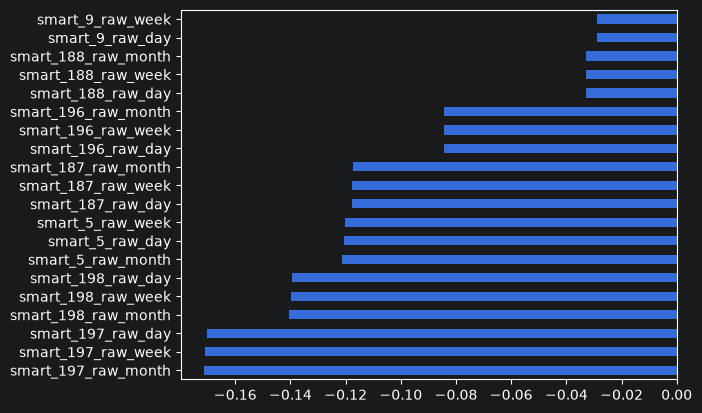

In [46]:
correlations.drop('fail').sort_values(key=abs, ascending=False).head(20).plot.barh()

In [47]:
def censored_mse(failed : pd.Series, y_pred : pd.Series, y_true : pd.Series, sample_weight : Optional[np.ndarray] =None):
    failed = np.asarray(failed, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    y_true = np.asarray(y_true, dtype=float)
    ans = np.zeros_like(y_pred)
    mask_failed = failed == 1
    ans[mask_failed] = np.power(y_pred[mask_failed] - y_true[mask_failed], 2)
    ans[~mask_failed] = np.where(y_pred[~mask_failed] >= y_true[~mask_failed], 0, np.power(y_pred[~mask_failed] - y_true[~mask_failed], 2))
    if sample_weight is None:
        return ans.mean()
    return (ans * sample_weight).sum() / sample_weight.sum()

there is a loss and metric draft above. Later it will be implemented in src.lossess like an objectives for XGBoost and CatBoost.

In [48]:
linear_regression = LinearRegression()

In [49]:
count_all = X_train.shape[0]
count_fail = X_train['fail'].sum()
weights = np.array([(count_all - count_fail) / count_fail if x else 1 for x in list(X_train['fail'])])

In [50]:
X_train.head()

,model,capacity_bytes,smart_1_raw_day,smart_2_raw_day,smart_3_raw_day,smart_4_raw_day,smart_5_raw_day,smart_7_raw_day,smart_8_raw_day,smart_9_raw_day,smart_10_raw_day,smart_11_raw_day,smart_12_raw_day,smart_13_raw_day,smart_16_raw_day,smart_17_raw_day,smart_22_raw_day,smart_27_raw_day,smart_82_raw_day,smart_90_raw_day,smart_165_raw_day,smart_166_raw_day,smart_167_raw_day,smart_168_raw_day,smart_169_raw_day,smart_170_raw_day,smart_171_raw_day,smart_172_raw_day,smart_173_raw_day,smart_174_raw_day,smart_175_raw_day,smart_177_raw_day,smart_179_raw_day,smart_180_raw_day,smart_181_raw_day,smart_183_raw_day,smart_184_raw_day,smart_187_raw_day,smart_188_raw_day,smart_189_raw_day,smart_190_raw_day,smart_191_raw_day,smart_192_raw_day,smart_193_raw_day,smart_194_raw_day,smart_195_raw_day,smart_196_raw_day,smart_197_raw_day,smart_198_raw_day,smart_199_raw_day,smart_200_raw_day,smart_201_raw_day,smart_202_raw_day,smart_206_raw_day,smart_211_raw_day,smart_212_raw_day,smart_218_raw_day,smart_220_raw_day,smart_222_raw_day,smart_223_raw_day,smart_225_raw_day,smart_226_raw_day,smart_230_raw_day,smart_231_raw_day,smart_232_raw_day,smart_233_raw_day,smart_234_raw_day,smart_235_raw_day,smart_240_raw_day,smart_241_raw_day,smart_242_raw_day,smart_245_raw_day,smart_246_raw_day,smart_247_raw_day,smart_248_raw_day,smart_1_raw_week,smart_2_raw_week,smart_3_raw_week,smart_4_raw_week,smart_5_raw_week,smart_7_raw_week,smart_8_raw_week,smart_9_raw_week,smart_10_raw_week,smart_11_raw_week,smart_12_raw_week,smart_13_raw_week,smart_16_raw_week,smart_17_raw_week,smart_22_raw_week,smart_27_raw_week,smart_82_raw_week,smart_90_raw_week,smart_165_raw_week,smart_166_raw_week,smart_167_raw_week,smart_168_raw_week,smart_169_raw_week,smart_170_raw_week,smart_171_raw_week,smart_172_raw_week,smart_173_raw_week,smart_174_raw_week,smart_175_raw_week,smart_177_raw_week,smart_179_raw_week,smart_180_raw_week,smart_181_raw_week,smart_183_raw_week,smart_184_raw_week,smart_187_raw_week,smart_188_raw_week,smart_189_raw_week,smart_190_raw_week,smart_191_raw_week,smart_192_raw_week,smart_193_raw_week,smart_194_raw_week,smart_195_raw_week,smart_196_raw_week,smart_197_raw_week,smart_198_raw_week,smart_199_raw_week,smart_200_raw_week,smart_201_raw_week,smart_202_raw_week,smart_206_raw_week,smart_211_raw_week,smart_212_raw_week,smart_218_raw_week,smart_220_raw_week,smart_222_raw_week,smart_223_raw_week,smart_225_raw_week,smart_226_raw_week,smart_230_raw_week,smart_231_raw_week,smart_232_raw_week,smart_233_raw_week,smart_234_raw_week,smart_235_raw_week,smart_240_raw_week,smart_241_raw_week,smart_242_raw_week,smart_245_raw_week,smart_246_raw_week,smart_247_raw_week,smart_248_raw_week,smart_1_raw_month,smart_2_raw_month,smart_3_raw_month,smart_4_raw_month,smart_5_raw_month,smart_7_raw_month,smart_8_raw_month,smart_9_raw_month,smart_10_raw_month,smart_11_raw_month,smart_12_raw_month,smart_13_raw_month,smart_16_raw_month,smart_17_raw_month,smart_22_raw_month,smart_27_raw_month,smart_82_raw_month,smart_90_raw_month,smart_165_raw_month,smart_166_raw_month,smart_167_raw_month,smart_168_raw_month,smart_169_raw_month,smart_170_raw_month,smart_171_raw_month,smart_172_raw_month,smart_173_raw_month,smart_174_raw_month,smart_175_raw_month,smart_177_raw_month,smart_179_raw_month,smart_180_raw_month,smart_181_raw_month,smart_183_raw_month,smart_184_raw_month,smart_187_raw_month,smart_188_raw_month,smart_189_raw_month,smart_190_raw_month,smart_191_raw_month,smart_192_raw_month,smart_193_raw_month,smart_194_raw_month,smart_195_raw_month,smart_196_raw_month,smart_197_raw_month,smart_198_raw_month,smart_199_raw_month,smart_200_raw_month,smart_201_raw_month,smart_202_raw_month,smart_206_raw_month,smart_211_raw_month,smart_212_raw_month,smart_218_raw_month,smart_220_raw_month,smart_222_raw_month,smart_223_raw_month,smart_225_raw_month,smart_226_raw_month,smart_230_raw_month,smart_231_raw_month,smart_232_raw_month,smart_233_raw_month,smart_234_raw_month,smart_235_raw_month,smart_240_raw_month,smart_241_raw_m

faced with problem: there is categorical feature, we should handle it.

In [51]:
models = X_train[['fail', 'model']].groupby('model').aggregate(['sum', 'count'])

In [52]:
models[models[('fail', 'count')] >= 500].count()

fail  sum      27
      count    27
dtype: int64

All the disks attached to rare models (fewer than 500 instances) do not fail, so we combine them into a single category" 'other'.

In [53]:
X_train['model'] = [md if models.loc[md][('fail','count')] >= 500 else 'other' for md in list(X_train['model'])]

In [60]:
features = X_train.columns.tolist()

transformer = ColumnTransformer(transformers=[
    ("categorical", OneHotEncoder(drop='first', handle_unknown='ignore'), ['model'])],
    remainder=StandardScaler()
)

In [61]:
def check_distribution_correctness(X, y):
    print('over 60:', len(y[y > 60]))
    print('in [59, 60]:', len(y[(59 <= y) & (y <= 60)]))
    print('under 59:', len(y[y < 59]))
    print('failed', X['fail'].sum())
    predicted_low_mask = y < 59
    actual_failed_mask = X['fail'] == 1
    print('failed and less than 59:', (predicted_low_mask & actual_failed_mask).sum())

In [62]:
def train_val_comparison(model, X_train, X_val):

    tr = clone(transformer)
    X_train_transformed = tr.fit_transform(X_train.drop(columns=['fail', 'rul_lb']))
    X_val_transformed = tr.transform(X_val.drop(columns=['fail', 'rul_lb']))
    # print(len(X_train.columns))
    # print(len(X_val.columns))
    md = clone(model)

    md.fit(X_train_transformed, X_train['rul_lb'], weights)

    y_pred_train = md.predict(X_train_transformed)
    y_pred_val = md.predict(X_val_transformed)

    print('on train:', censored_mse(X_train['fail'], y_pred_train, X_train['rul_lb']))
    print('on val:', censored_mse(X_val['fail'], y_pred_val, X_val['rul_lb']))
    print('train')
    check_distribution_correctness(X_train, y_pred_train)
    print('val')
    check_distribution_correctness(X_val, y_pred_val)

In [63]:
for model in [LinearRegression(), Ridge(), ElasticNet()]:
    train_val_comparison(model, X_train, X_val)

/Users/zarubin/PycharmProjects/RUL_HDD/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


on train: 130.9161322648295
on val: 130.79571208851817
train
over 60: 6261
in [59, 60]: 3568
under 59: 203563
failed 469
failed and less than 59: 467
val
over 60: 1570
in [59, 60]: 650
under 59: 43508
failed 100
failed and less than 59: 99


/Users/zarubin/PycharmProjects/RUL_HDD/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


on train: 130.97783704267536
on val: 130.96515718817668
train
over 60: 6175
in [59, 60]: 3560
under 59: 203657
failed 469
failed and less than 59: 467
val
over 60: 1551
in [59, 60]: 654
under 59: 43523
failed 100
failed and less than 59: 99


/Users/zarubin/PycharmProjects/RUL_HDD/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


on train: 145.36794830509666
on val: 147.15612859616863
train
over 60: 14
in [59, 60]: 2
under 59: 213376
failed 469
failed and less than 59: 469
val
over 60: 2
in [59, 60]: 0
under 59: 45726
failed 100
failed and less than 59: 100


We tried three linear regression alternatives: no regulatization, with L2 (Ridge) ans with L1 and L2 (ElasticNet). All the models give similar values on train and validation, the best model gives ~ 130 CMSE that is approximately ~11.4 days RMSE.

Now let's see how week and day averaged features influence on training.

In [64]:
chosen = features[:2] + features[-74:]
X_partial = X_train[chosen]
X_val_partial = X_val[chosen]
X_partial.head()

,model,capacity_bytes,smart_2_raw_month,smart_3_raw_month,smart_4_raw_month,smart_5_raw_month,smart_7_raw_month,smart_8_raw_month,smart_9_raw_month,smart_10_raw_month,smart_11_raw_month,smart_12_raw_month,smart_13_raw_month,smart_16_raw_month,smart_17_raw_month,smart_22_raw_month,smart_27_raw_month,smart_82_raw_month,smart_90_raw_month,smart_165_raw_month,smart_166_raw_month,smart_167_raw_month,smart_168_raw_month,smart_169_raw_month,smart_170_raw_month,smart_171_raw_month,smart_172_raw_month,smart_173_raw_month,smart_174_raw_month,smart_175_raw_month,smart_177_raw_month,smart_179_raw_month,smart_180_raw_month,smart_181_raw_month,smart_183_raw_month,smart_184_raw_month,smart_187_raw_month,smart_188_raw_month,smart_189_raw_month,smart_190_raw_month,smart_191_raw_month,smart_192_raw_month,smart_193_raw_month,smart_194_raw_month,smart_195_raw_month,smart_196_raw_month,smart_197_raw_month,smart_198_raw_month,smart_199_raw_month,smart_200_raw_month,smart_201_raw_month,smart_202_raw_month,smart_206_raw_month,smart_211_raw_month,smart_212_raw_month,smart_218_raw_month,smart_220_raw_month,smart_222_raw_month,smart_223_raw_month,smart_225_raw_month,smart_226_raw_month,smart_230_raw_month,smart_231_raw_month,smart_232_raw_month,smart_233_raw_month,smart_234_raw_month,smart_235_raw_month,smart_240_raw_month,smart_241_raw_month,smart_242_raw_month,smart_245_raw_month,smart_246_raw_month,smart_247_raw_month,smart_248_raw_month,rul_lb,fail
serial_number,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
ZLW18RLG,ST14000NM001G,14000519643136,0.0,0.0,1364.0,0.0,1.813983e+10,0.0,1171728.0,0.0,0.0,1364.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1139.0,0.0,1240.0,75436.0,1139.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1156663.0,4.104303e+12,1.488437e+13,0.0,0.0,0.0,0.0,60,False
2GJ2WX7G,WDC WUH722222ALE6L4,22000969973760,1486.0,10571.0,310.0,0.0,0.000000e+00,465.0,254941.0,0.0,0.0,310.0,0.0,0.0,0.0,203164700.0,0.0,0.0,1.584413e+13,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,11595.0,11595.0,1061.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0,60,False
3080A02PF97G,TOSHIBA MG07ACA14TA,14000519643136,0.0,243536.0,186.0,0.0,0.000000e+00,0.0,1222995.0,0.0,0.0,186.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6107.0,93.0,434.0,860.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.985193e+09,1217483.0,0.0,0.0,18259.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0,60,False
1050A07RF97G,TOSHIBA MG07ACA14TA,14000519643136,0.0,240963.0,124.0,0.0,0.000000e+00,0.0,1136694.0,0.0,0.0,124.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,62.0,62.0,372.0,959.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.186412e+09,1134090.0,0.0,0.0,18259.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.0,60,False
ZL0055F1,ST12000NM0008,12000138625024,0.0,0.0,465.0,9176.0,2.171764e+09,0.0,1198498.0,0.0,0.0,465.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,836.0,0.0,217.0,60409.0,836.0,3.899471e+09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1190685.0,2.908202e+12,1.359557e+13,0.0,0.0,0.0,0.0,60,False


In [65]:
for model in [LinearRegression(), Ridge(), ElasticNet()]:
    train_val_comparison(model, X_partial, X_val_partial)

/Users/zarubin/PycharmProjects/RUL_HDD/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


on train: 141.86513629173976
on val: 143.25248185869222
train
over 60: 4076
in [59, 60]: 2429
under 59: 206887
failed 469
failed and less than 59: 469
val
over 60: 1072
in [59, 60]: 449
under 59: 44207
failed 100
failed and less than 59: 99


/Users/zarubin/PycharmProjects/RUL_HDD/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


on train: 141.858500150318
on val: 143.2908791394354
train
over 60: 4067
in [59, 60]: 2424
under 59: 206901
failed 469
failed and less than 59: 469
val
over 60: 1066
in [59, 60]: 440
under 59: 44222
failed 100
failed and less than 59: 99
on train: 150.04440748943074
on val: 151.52058717153508
train
over 60: 12
in [59, 60]: 1
under 59: 213379
failed 469
failed and less than 59: 469
val
over 60: 2
in [59, 60]: 0
under 59: 45726
failed 100
failed and less than 59: 100


/Users/zarubin/PycharmProjects/RUL_HDD/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Dropping third of features gives fourfold speedup(8s → 2s) and just little CMSE increase (+11 that is ~ +0.5 day RMSE). But it does not imply that we can train more powerful models by cutting 2/3 of the features. Boosting models can have different feature importances and extract more information from features.

In [66]:
X_train.to_csv('../data/processed/X_train.csv', index=False)